## 1. Import Required Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import cv2
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Set style for publication-quality plots
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

print("✓ Libraries imported successfully")
print(f"NumPy Version: {np.__version__}")
print(f"Pandas Version: {pd.__version__}")

✓ Libraries imported successfully
NumPy Version: 2.2.6
Pandas Version: 2.3.3


## 2. Configuration and Parameters

In [3]:
# Dataset configuration
DATA_PATH = '../data'
CLASSES = ['0_percent', '25_percent', '50_percent', '100_percent']
NUM_CLASSES = len(CLASSES)

# Image parameters
IMG_HEIGHT = 224
IMG_WIDTH = 224
IMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)

# Color palette for visualizations
COLORS = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4']

print("Configuration:")
print(f"Dataset Path: {DATA_PATH}")
print(f"Classes: {CLASSES}")
print(f"Target Image Size: {IMG_SIZE}")

Configuration:
Dataset Path: ../data
Classes: ['0_percent', '25_percent', '50_percent', '100_percent']
Target Image Size: (224, 224)


## 3. Dataset Overview and Statistics

In [4]:
def count_images(data_path, classes):
    """Count images in each class folder"""
    image_counts = {}
    total_size = 0
    
    for class_name in classes:
        class_path = os.path.join(data_path, class_name)
        if os.path.exists(class_path):
            images = [f for f in os.listdir(class_path) 
                     if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tiff'))]
            image_counts[class_name] = len(images)
            
            # Calculate folder size
            for img in images:
                img_path = os.path.join(class_path, img)
                total_size += os.path.getsize(img_path)
        else:
            image_counts[class_name] = 0
    
    return image_counts, total_size

# Count images
image_counts, dataset_size = count_images(DATA_PATH, CLASSES)
total_images = sum(image_counts.values())

# Create summary DataFrame
df_counts = pd.DataFrame(list(image_counts.items()), columns=['Feed Level', 'Image Count'])
df_counts['Percentage'] = (df_counts['Image Count'] / total_images * 100).round(2)

print("\n" + "="*70)
print("DATASET STATISTICS")
print("="*70)
print(f"\nTotal Images: {total_images:,}")
print(f"Dataset Size: {dataset_size / (1024*1024):.2f} MB")
print(f"Number of Classes: {NUM_CLASSES}")
print(f"\nDistribution per Class:")
print("-"*70)
print(df_counts.to_string(index=False))
print("="*70)


DATASET STATISTICS

Total Images: 1,500
Dataset Size: 883.87 MB
Number of Classes: 4

Distribution per Class:
----------------------------------------------------------------------
 Feed Level  Image Count  Percentage
  0_percent          300       20.00
 25_percent          400       26.67
 50_percent          400       26.67
100_percent          400       26.67


## 4. Class Distribution Visualization
### Publication-Quality Figure 1: Dataset Distribution

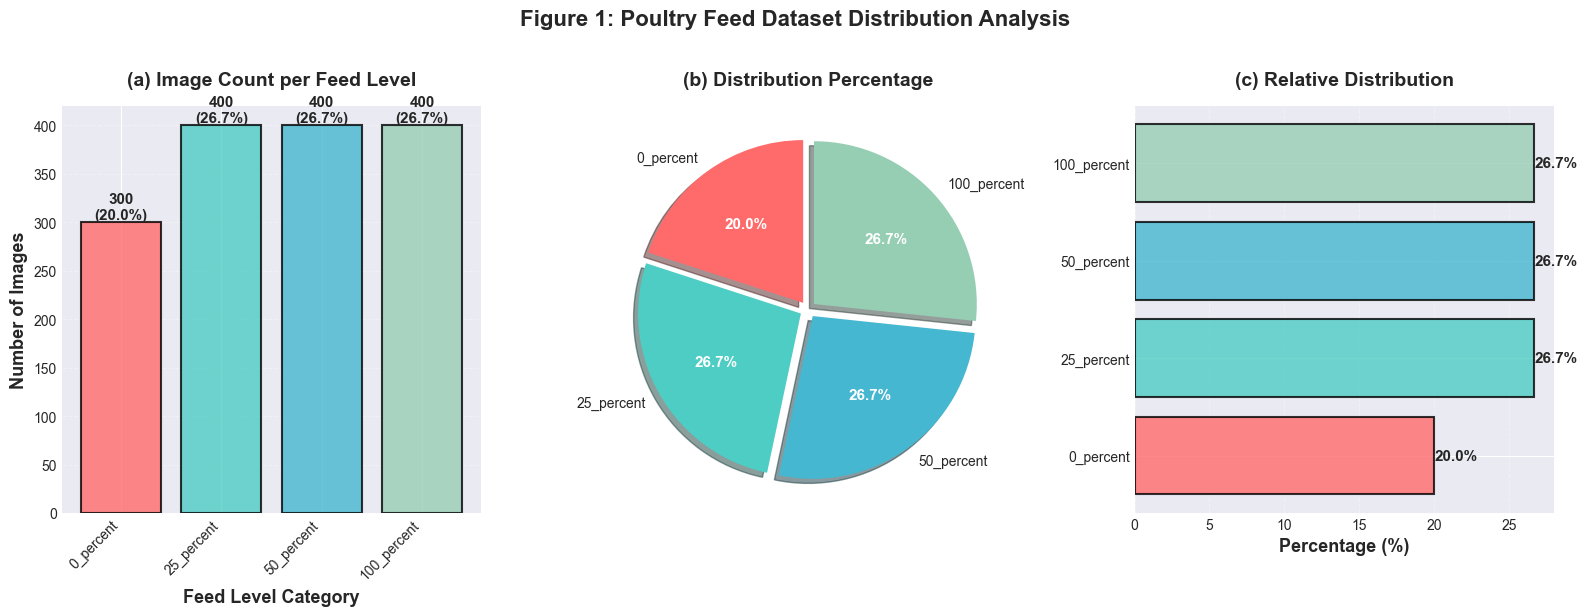

✓ Figure 1 saved: fig1_dataset_distribution.png


In [5]:
fig = plt.figure(figsize=(16, 6))

# Subplot 1: Bar Chart
ax1 = plt.subplot(1, 3, 1)
bars = ax1.bar(range(len(CLASSES)), list(image_counts.values()), 
               color=COLORS, alpha=0.8, edgecolor='black', linewidth=1.5)
ax1.set_xlabel('Feed Level Category', fontsize=13, fontweight='bold')
ax1.set_ylabel('Number of Images', fontsize=13, fontweight='bold')
ax1.set_title('(a) Image Count per Feed Level', fontsize=14, fontweight='bold', pad=15)
ax1.set_xticks(range(len(CLASSES)))
ax1.set_xticklabels(CLASSES, rotation=45, ha='right')
ax1.grid(axis='y', alpha=0.3, linestyle='--')

# Add value labels on bars
for i, (bar, count) in enumerate(zip(bars, image_counts.values())):
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height,
             f'{count}\n({count/total_images*100:.1f}%)',
             ha='center', va='bottom', fontsize=11, fontweight='bold')

# Subplot 2: Pie Chart
ax2 = plt.subplot(1, 3, 2)
wedges, texts, autotexts = ax2.pie(image_counts.values(), 
                                     labels=CLASSES,
                                     autopct='%1.1f%%',
                                     colors=COLORS,
                                     startangle=90,
                                     explode=(0.05, 0.05, 0.05, 0.05),
                                     shadow=True)
ax2.set_title('(b) Distribution Percentage', fontsize=14, fontweight='bold', pad=15)
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')
    autotext.set_fontsize(11)

# Subplot 3: Horizontal Bar Chart with Percentage
ax3 = plt.subplot(1, 3, 3)
y_pos = np.arange(len(CLASSES))
percentages = [count/total_images*100 for count in image_counts.values()]
bars3 = ax3.barh(y_pos, percentages, color=COLORS, alpha=0.8, 
                 edgecolor='black', linewidth=1.5)
ax3.set_yticks(y_pos)
ax3.set_yticklabels(CLASSES)
ax3.set_xlabel('Percentage (%)', fontsize=13, fontweight='bold')
ax3.set_title('(c) Relative Distribution', fontsize=14, fontweight='bold', pad=15)
ax3.grid(axis='x', alpha=0.3, linestyle='--')

# Add percentage labels
for i, (bar, pct) in enumerate(zip(bars3, percentages)):
    width = bar.get_width()
    ax3.text(width, bar.get_y() + bar.get_height()/2.,
             f'{pct:.1f}%',
             ha='left', va='center', fontsize=11, fontweight='bold')

plt.suptitle('Figure 1: Poultry Feed Dataset Distribution Analysis', 
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../results/visualizations/fig1_dataset_distribution.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print("✓ Figure 1 saved: fig1_dataset_distribution.png")

## 5. Sample Image Analysis
### Figure 2: Representative Samples from Each Feed Level

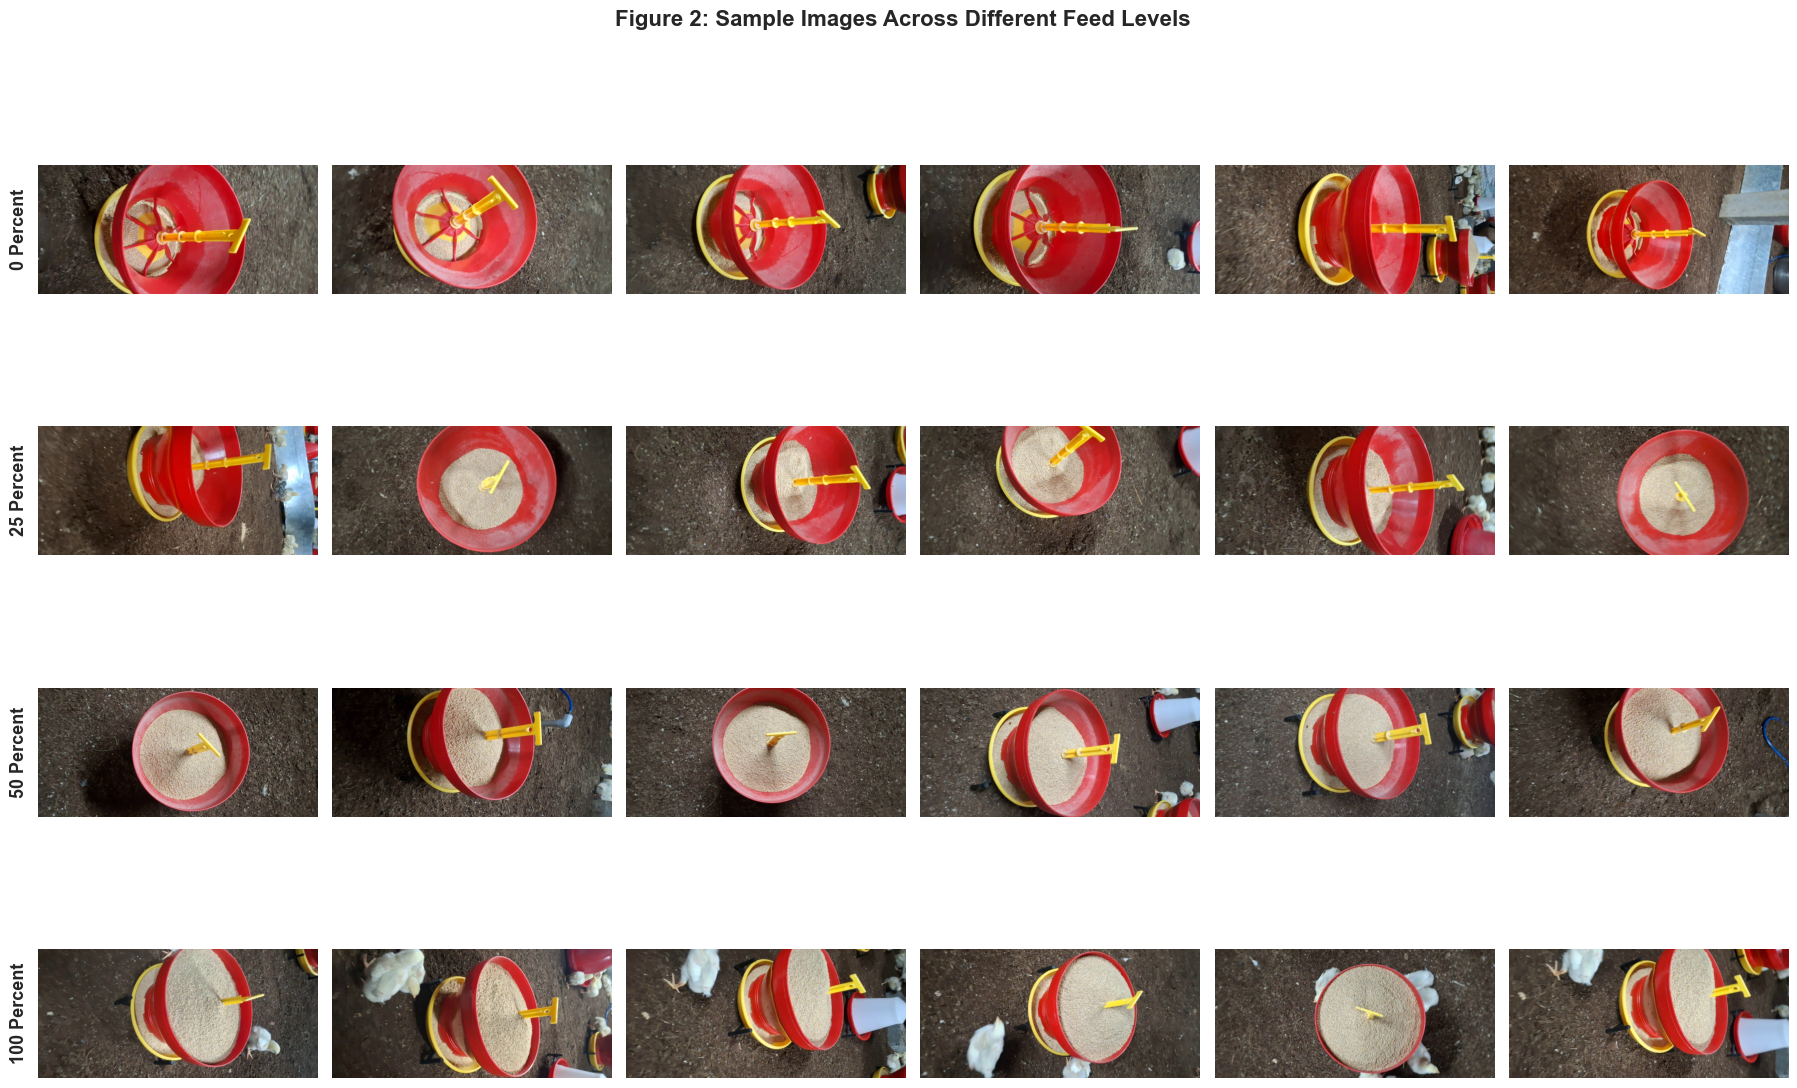

✓ Figure 2 saved: fig2_sample_images.png


In [6]:
fig, axes = plt.subplots(4, 6, figsize=(18, 12))
fig.suptitle('Figure 2: Sample Images Across Different Feed Levels', 
             fontsize=16, fontweight='bold', y=0.995)

for idx, class_name in enumerate(CLASSES):
    class_path = os.path.join(DATA_PATH, class_name)
    if os.path.exists(class_path):
        images = [f for f in os.listdir(class_path) 
                 if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tiff'))]
        
        # Select 6 random samples
        samples = np.random.choice(images, min(6, len(images)), replace=False)
        
        for i, img_name in enumerate(samples):
            img_path = os.path.join(class_path, img_name)
            img = cv2.imread(img_path)
            if img is not None:
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                axes[idx, i].imshow(img)
                axes[idx, i].axis('off')
                
                # Add title to first image of each row
                if i == 0:
                    axes[idx, i].text(-0.1, 0.5, class_name.replace('_', ' ').title(), 
                                     transform=axes[idx, i].transAxes,
                                     fontsize=13, fontweight='bold',
                                     va='center', rotation=90)

plt.tight_layout()
plt.savefig('../results/visualizations/fig2_sample_images.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print("✓ Figure 2 saved: fig2_sample_images.png")

## 6. Image Properties Analysis
### Figure 3: Image Dimension and Size Statistics

In [7]:
def analyze_image_properties(data_path, classes, sample_size=100):
    """Analyze image dimensions and file sizes"""
    widths, heights, file_sizes, categories = [], [], [], []
    
    for class_name in classes:
        class_path = os.path.join(data_path, class_name)
        if os.path.exists(class_path):
            images = [f for f in os.listdir(class_path) 
                     if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tiff'))]
            
            # Sample images for analysis
            samples = np.random.choice(images, min(sample_size, len(images)), replace=False)
            
            for img_name in samples:
                img_path = os.path.join(class_path, img_name)
                img = cv2.imread(img_path)
                if img is not None:
                    h, w = img.shape[:2]
                    widths.append(w)
                    heights.append(h)
                    file_sizes.append(os.path.getsize(img_path) / 1024)  # KB
                    categories.append(class_name)
    
    return widths, heights, file_sizes, categories

print("Analyzing image properties (sampling 100 images per class)...")
widths, heights, file_sizes, categories = analyze_image_properties(DATA_PATH, CLASSES)

# Create analysis DataFrame
df_props = pd.DataFrame({
    'Width': widths,
    'Height': heights,
    'File Size (KB)': file_sizes,
    'Category': categories
})

# Statistical summary
print("\nImage Properties Summary:")
print("="*70)
print(df_props.describe())
print("="*70)

Analyzing image properties (sampling 100 images per class)...

Image Properties Summary:
        Width  Height  File Size (KB)
count   400.0   400.0      400.000000
mean   2336.0  1080.0      594.954834
std       0.0     0.0       87.341590
min    2336.0  1080.0      381.093750
25%    2336.0  1080.0      533.027100
50%    2336.0  1080.0      586.532715
75%    2336.0  1080.0      649.848145
max    2336.0  1080.0      829.910156


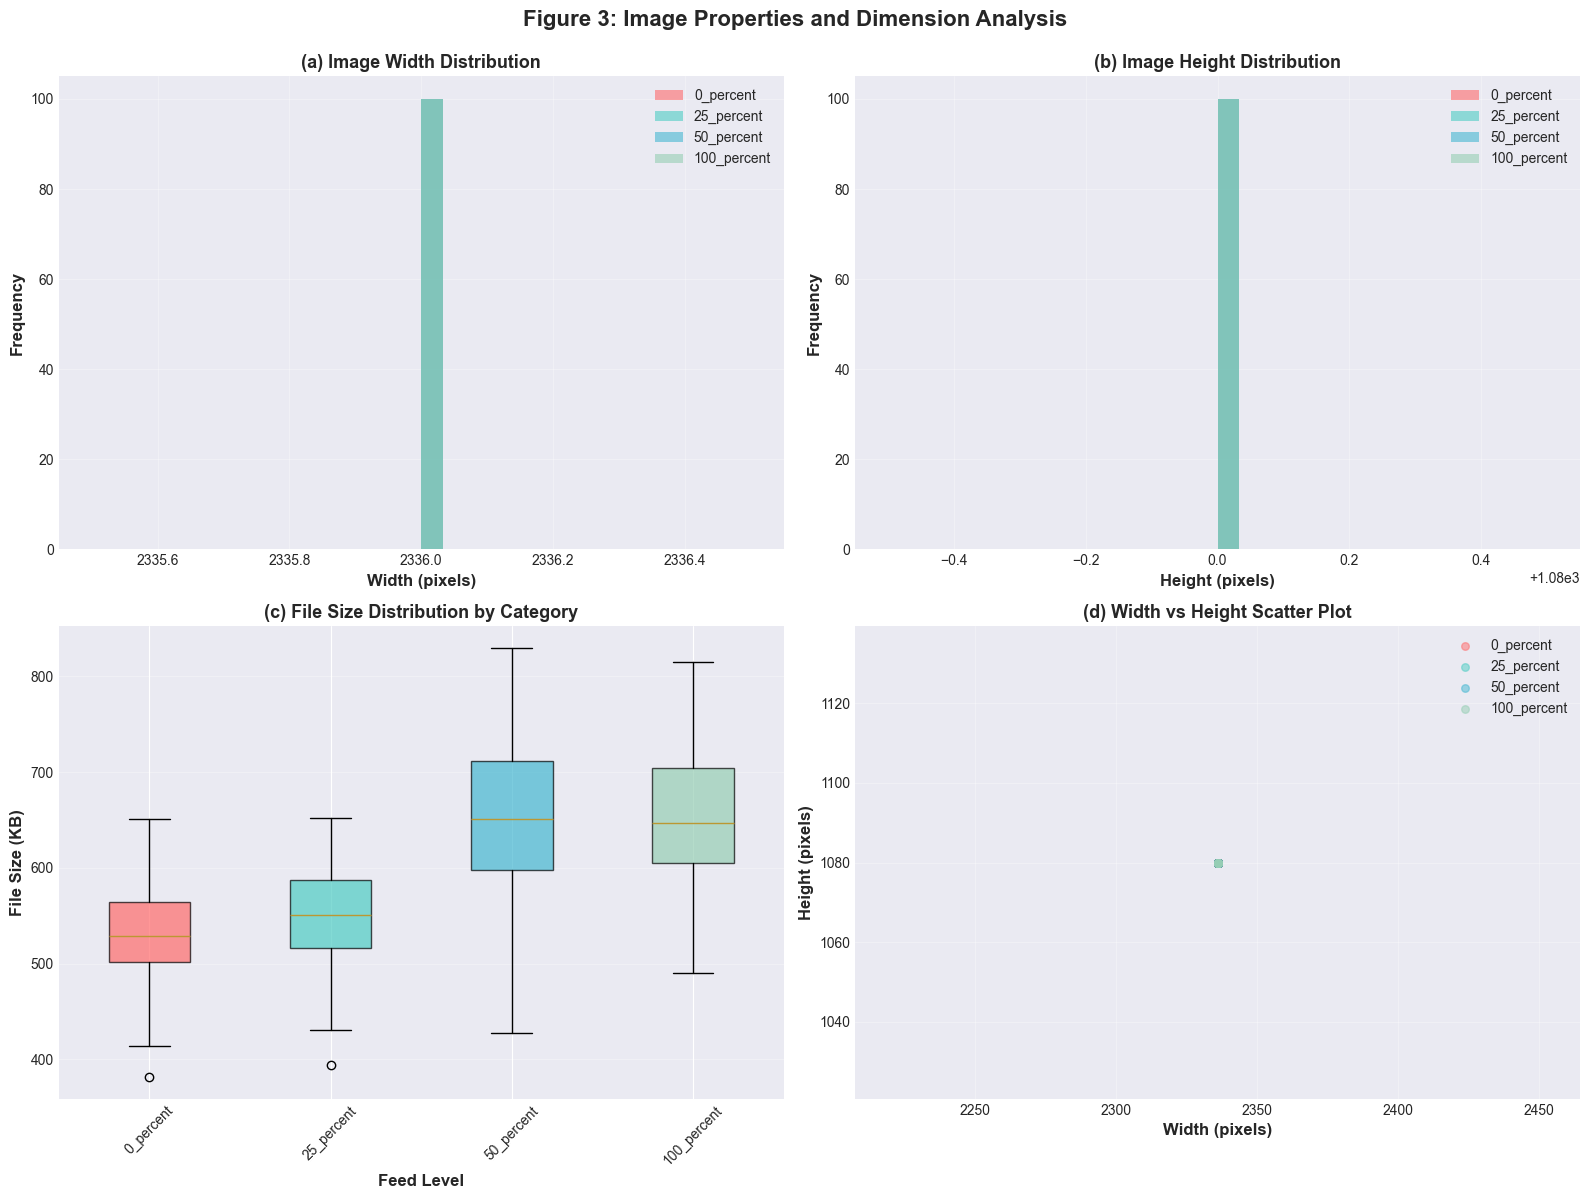

✓ Figure 3 saved: fig3_image_properties.png


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Subplot 1: Width Distribution
ax1 = axes[0, 0]
for i, class_name in enumerate(CLASSES):
    class_data = df_props[df_props['Category'] == class_name]['Width']
    ax1.hist(class_data, bins=30, alpha=0.6, label=class_name, color=COLORS[i])
ax1.set_xlabel('Width (pixels)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Frequency', fontsize=12, fontweight='bold')
ax1.set_title('(a) Image Width Distribution', fontsize=13, fontweight='bold')
ax1.legend()
ax1.grid(alpha=0.3)

# Subplot 2: Height Distribution
ax2 = axes[0, 1]
for i, class_name in enumerate(CLASSES):
    class_data = df_props[df_props['Category'] == class_name]['Height']
    ax2.hist(class_data, bins=30, alpha=0.6, label=class_name, color=COLORS[i])
ax2.set_xlabel('Height (pixels)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Frequency', fontsize=12, fontweight='bold')
ax2.set_title('(b) Image Height Distribution', fontsize=13, fontweight='bold')
ax2.legend()
ax2.grid(alpha=0.3)

# Subplot 3: File Size Box Plot
ax3 = axes[1, 0]
bp = ax3.boxplot([df_props[df_props['Category'] == c]['File Size (KB)'] for c in CLASSES],
                  labels=CLASSES, patch_artist=True)
for patch, color in zip(bp['boxes'], COLORS):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax3.set_xlabel('Feed Level', fontsize=12, fontweight='bold')
ax3.set_ylabel('File Size (KB)', fontsize=12, fontweight='bold')
ax3.set_title('(c) File Size Distribution by Category', fontsize=13, fontweight='bold')
ax3.tick_params(axis='x', rotation=45)
ax3.grid(alpha=0.3, axis='y')

# Subplot 4: Aspect Ratio Scatter
ax4 = axes[1, 1]
for i, class_name in enumerate(CLASSES):
    class_data = df_props[df_props['Category'] == class_name]
    ax4.scatter(class_data['Width'], class_data['Height'], 
               alpha=0.5, label=class_name, color=COLORS[i], s=30)
ax4.set_xlabel('Width (pixels)', fontsize=12, fontweight='bold')
ax4.set_ylabel('Height (pixels)', fontsize=12, fontweight='bold')
ax4.set_title('(d) Width vs Height Scatter Plot', fontsize=13, fontweight='bold')
ax4.legend()
ax4.grid(alpha=0.3)

plt.suptitle('Figure 3: Image Properties and Dimension Analysis', 
             fontsize=16, fontweight='bold', y=0.995)
plt.tight_layout()
plt.savefig('../results/visualizations/fig3_image_properties.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print("✓ Figure 3 saved: fig3_image_properties.png")

## 7. Color Space Analysis
### Figure 4: RGB Channel Distribution

Analyzing color distributions (50 samples per class)...


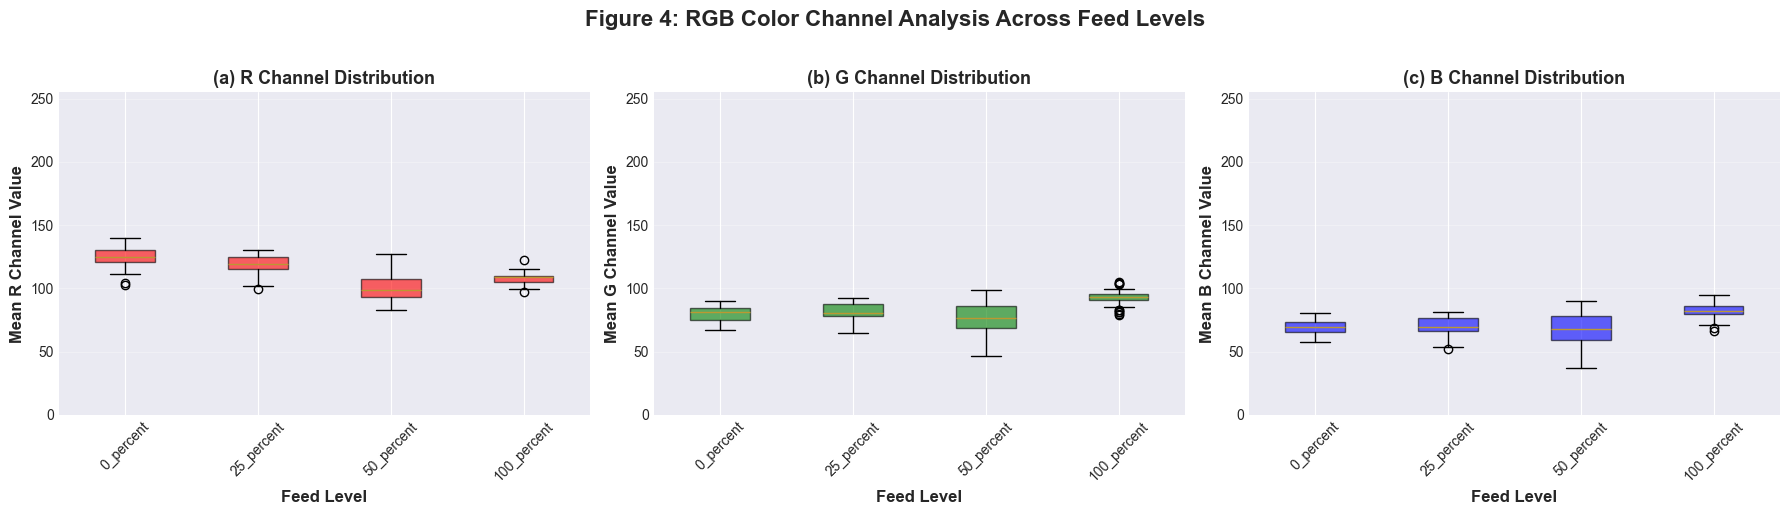

✓ Figure 4 saved: fig4_color_analysis.png


In [9]:
def analyze_color_distribution(data_path, classes, samples_per_class=50):
    """Analyze RGB channel distributions"""
    color_stats = {class_name: {'R': [], 'G': [], 'B': []} for class_name in classes}
    
    for class_name in classes:
        class_path = os.path.join(data_path, class_name)
        if os.path.exists(class_path):
            images = [f for f in os.listdir(class_path) 
                     if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tiff'))]
            
            samples = np.random.choice(images, min(samples_per_class, len(images)), replace=False)
            
            for img_name in samples:
                img_path = os.path.join(class_path, img_name)
                img = cv2.imread(img_path)
                if img is not None:
                    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                    color_stats[class_name]['R'].append(np.mean(img_rgb[:,:,0]))
                    color_stats[class_name]['G'].append(np.mean(img_rgb[:,:,1]))
                    color_stats[class_name]['B'].append(np.mean(img_rgb[:,:,2]))
    
    return color_stats

print("Analyzing color distributions (50 samples per class)...")
color_stats = analyze_color_distribution(DATA_PATH, CLASSES)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
channels = ['R', 'G', 'B']
channel_colors = ['red', 'green', 'blue']

for idx, (channel, color) in enumerate(zip(channels, channel_colors)):
    ax = axes[idx]
    data = [color_stats[class_name][channel] for class_name in CLASSES]
    
    bp = ax.boxplot(data, labels=CLASSES, patch_artist=True)
    for patch in bp['boxes']:
        patch.set_facecolor(color)
        patch.set_alpha(0.6)
    
    ax.set_xlabel('Feed Level', fontsize=12, fontweight='bold')
    ax.set_ylabel(f'Mean {channel} Channel Value', fontsize=12, fontweight='bold')
    ax.set_title(f'({chr(97+idx)}) {channel} Channel Distribution', 
                fontsize=13, fontweight='bold')
    ax.tick_params(axis='x', rotation=45)
    ax.grid(alpha=0.3, axis='y')
    ax.set_ylim([0, 255])

plt.suptitle('Figure 4: RGB Color Channel Analysis Across Feed Levels', 
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../results/visualizations/fig4_color_analysis.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print("✓ Figure 4 saved: fig4_color_analysis.png")

## 8. Data Quality Assessment

In [10]:
def check_data_quality(data_path, classes):
    """Check for corrupted images and data quality issues"""
    quality_report = {
        'total': 0,
        'readable': 0,
        'corrupted': 0,
        'corrupted_files': []
    }
    
    for class_name in classes:
        class_path = os.path.join(data_path, class_name)
        if os.path.exists(class_path):
            images = [f for f in os.listdir(class_path) 
                     if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tiff'))]
            
            for img_name in images:
                img_path = os.path.join(class_path, img_name)
                quality_report['total'] += 1
                
                try:
                    img = cv2.imread(img_path)
                    if img is not None and img.size > 0:
                        quality_report['readable'] += 1
                    else:
                        quality_report['corrupted'] += 1
                        quality_report['corrupted_files'].append(img_path)
                except Exception as e:
                    quality_report['corrupted'] += 1
                    quality_report['corrupted_files'].append(img_path)
    
    return quality_report

print("Performing data quality check...")
quality_report = check_data_quality(DATA_PATH, CLASSES)

print("\n" + "="*70)
print("DATA QUALITY REPORT")
print("="*70)
print(f"Total Images Checked: {quality_report['total']:,}")
print(f"Readable Images: {quality_report['readable']:,} ({quality_report['readable']/quality_report['total']*100:.2f}%)")
print(f"Corrupted Images: {quality_report['corrupted']}")

if quality_report['corrupted'] > 0:
    print("\nCorrupted Files:")
    for file in quality_report['corrupted_files']:
        print(f"  - {file}")
else:
    print("\n✓ All images are readable and valid!")
print("="*70)

Performing data quality check...

DATA QUALITY REPORT
Total Images Checked: 1,500
Readable Images: 1,500 (100.00%)
Corrupted Images: 0

✓ All images are readable and valid!


## 9. Summary Statistics for Research Paper

In [11]:
# Create comprehensive summary table
summary_data = []
for class_name in CLASSES:
    class_data = df_props[df_props['Category'] == class_name]
    summary_data.append({
        'Feed Level': class_name.replace('_', ' ').title(),
        'Image Count': image_counts[class_name],
        'Percentage': f"{image_counts[class_name]/total_images*100:.2f}%",
        'Avg Width': f"{class_data['Width'].mean():.0f}px",
        'Avg Height': f"{class_data['Height'].mean():.0f}px",
        'Avg File Size': f"{class_data['File Size (KB)'].mean():.2f}KB"
    })

df_summary = pd.DataFrame(summary_data)

print("\n" + "="*90)
print("TABLE 1: DATASET SUMMARY STATISTICS FOR RESEARCH PAPER")
print("="*90)
print(df_summary.to_string(index=False))
print("="*90)

# Save to CSV
df_summary.to_csv('../results/metrics/dataset_summary.csv', index=False)
print("\n✓ Summary table saved: dataset_summary.csv")


TABLE 1: DATASET SUMMARY STATISTICS FOR RESEARCH PAPER
 Feed Level  Image Count Percentage Avg Width Avg Height Avg File Size
  0 Percent          300     20.00%    2336px     1080px      528.22KB
 25 Percent          400     26.67%    2336px     1080px      548.25KB
 50 Percent          400     26.67%    2336px     1080px      652.47KB
100 Percent          400     26.67%    2336px     1080px      650.88KB

✓ Summary table saved: dataset_summary.csv


## 10. Key Findings and Recommendations

In [12]:
print("\n" + "="*70)
print("KEY FINDINGS - EXPLORATORY DATA ANALYSIS")
print("="*70)

print("\n1. Dataset Composition:")
print(f"   - Total samples: {total_images:,} images across {NUM_CLASSES} feed levels")
print(f"   - Dataset size: {dataset_size / (1024*1024):.2f} MB")
print(f"   - Data quality: {quality_report['readable']/quality_report['total']*100:.1f}% valid images")

print("\n2. Class Balance:")
max_class = max(image_counts, key=image_counts.get)
min_class = min(image_counts, key=image_counts.get)
imbalance_ratio = image_counts[max_class] / image_counts[min_class]
print(f"   - Most represented: {max_class} ({image_counts[max_class]} images)")
print(f"   - Least represented: {min_class} ({image_counts[min_class]} images)")
print(f"   - Imbalance ratio: {imbalance_ratio:.2f}:1")

if imbalance_ratio > 1.5:
    print("   ⚠ Recommendation: Consider data augmentation for minority classes")
else:
    print("   ✓ Classes are well-balanced")

print("\n3. Image Properties:")
print(f"   - Average dimensions: {df_props['Width'].mean():.0f}×{df_props['Height'].mean():.0f} pixels")
print(f"   - Target size for training: {IMG_WIDTH}×{IMG_HEIGHT} pixels")
print(f"   - Average file size: {df_props['File Size (KB)'].mean():.2f} KB")

print("\n4. Recommendations for Model Training:")
print("   ✓ Dataset is suitable for deep learning")
print("   ✓ Apply data augmentation to improve model generalization")
print("   ✓ Use stratified train-validation split to maintain class balance")
print(f"   ✓ Resize all images to {IMG_WIDTH}×{IMG_HEIGHT} for consistency")
print("   ✓ Consider transfer learning for better performance")

print("\n" + "="*70)
print("✓ Exploratory Data Analysis Complete!")
print("="*70)


KEY FINDINGS - EXPLORATORY DATA ANALYSIS

1. Dataset Composition:
   - Total samples: 1,500 images across 4 feed levels
   - Dataset size: 883.87 MB
   - Data quality: 100.0% valid images

2. Class Balance:
   - Most represented: 25_percent (400 images)
   - Least represented: 0_percent (300 images)
   - Imbalance ratio: 1.33:1
   ✓ Classes are well-balanced

3. Image Properties:
   - Average dimensions: 2336×1080 pixels
   - Target size for training: 224×224 pixels
   - Average file size: 594.95 KB

4. Recommendations for Model Training:
   ✓ Dataset is suitable for deep learning
   ✓ Apply data augmentation to improve model generalization
   ✓ Use stratified train-validation split to maintain class balance
   ✓ Resize all images to 224×224 for consistency
   ✓ Consider transfer learning for better performance

✓ Exploratory Data Analysis Complete!


---
## Conclusion

This exploratory analysis has provided comprehensive insights into the poultry feed dataset:

1. **Dataset Quality**: All images verified and validated
2. **Distribution**: Class distribution analyzed and documented
3. **Properties**: Image dimensions and color characteristics examined
4. **Readiness**: Dataset confirmed ready for deep learning model training

**Next Steps:**
- Proceed to Model Training notebooks (Custom CNN, ResNet50, MobileNetV2)
- Implement data augmentation strategies
- Conduct comparative model analysis

---
*Generated for Final Year Research Project - Feed Optimization and Growth Prediction System*